# (3030AFE) Assignment 2 (2026)
---
**Name:** *Tien Dat Ly*

**Student ID:** *S5411867*

---

In [37]:
# libraries
# essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('seaborn-v0_8-white')
sns.set_style('whitegrid')

# statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf

# sklearn librabries
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, LassoCV, LogisticRegressionCV 
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_squared_error as MSE, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier 
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier

In [38]:
# load data
rp = pd.read_csv("Retail_Preference_2026.csv")
rp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1386 entries, 0 to 1385
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PremiumShare  1386 non-null   float64
 1   ValueShare    1386 non-null   float64
 2   male          1386 non-null   int64  
 3   age           1386 non-null   int64  
 4   quality       1386 non-null   int64  
 5   brand         1386 non-null   int64  
 6   income        1386 non-null   float64
 7   education     1386 non-null   int64  
 8   Item_price    1386 non-null   float64
dtypes: float64(4), int64(5)
memory usage: 97.6 KB


# Question 1

In [39]:
#1
rp['Preference'] = np.log(rp['PremiumShare'] / rp['ValueShare'])
rp.head()

,PremiumShare,ValueShare,male,age,quality,brand,income,education,Item_price,Preference
0,0.30,0.70,1,30,2,1,75.904118,1,17.446430,-0.847298
1,0.60,0.40,1,71,3,2,104.654721,1,18.970078,0.405465
2,0.06,0.94,0,36,3,3,70.631999,2,14.438011,-2.751535
3,0.50,0.50,0,28,2,1,171.700623,2,18.535390,0.000000
4,0.50,0.50,0,23,3,1,27.081408,2,21.652729,0.000000


<Axes: xlabel='Item_price', ylabel='Preference'>

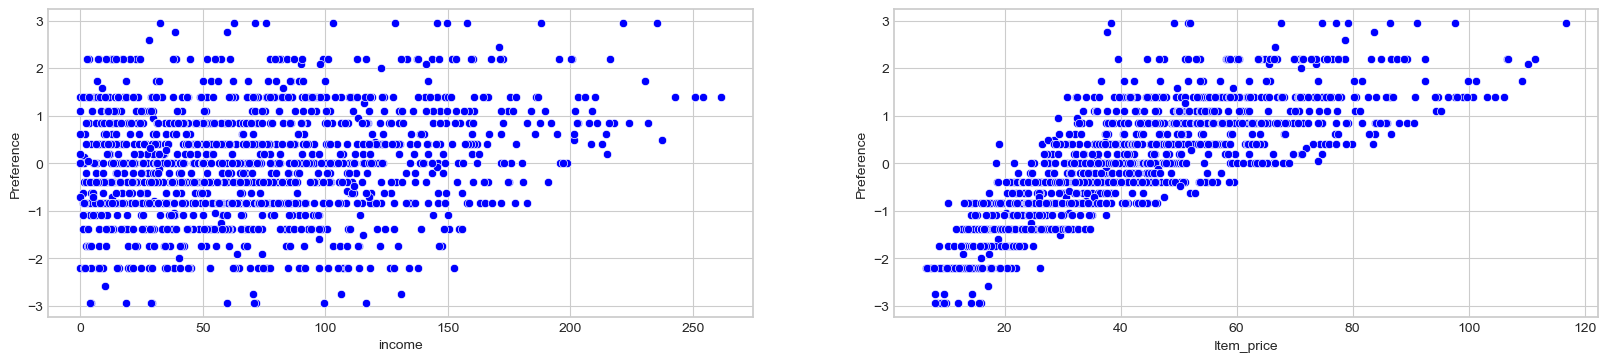

In [40]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(20,4))
sns.scatterplot(x='income',y='Preference', data=rp, color='blue', ax=ax1)
sns.scatterplot(x='Item_price',y='Preference', data=rp, color='blue', ax=ax2)

**Discussion**

Preference vs. income: The relationship does not appear to be linear. The scatterplot shows a diffuse cloud of points without a discernible straight-line trend.   

Preference vs. Item_price: The relationship does appear to be linear. The scatterplot displays a clear upward, proportional trend where higher item prices correspond directly to higher values of Preference. 

In [41]:
#2
rp=pd.get_dummies(rp,columns=['quality','brand','education'], drop_first=True)
rp.info

<bound method DataFrame.info of       PremiumShare  ValueShare  male  age      income  Item_price  Preference  \
0             0.30        0.70     1   30   75.904118   17.446430   -0.847298   
1             0.60        0.40     1   71  104.654721   18.970078    0.405465   
2             0.06        0.94     0   36   70.631999   14.438011   -2.751535   
3             0.50        0.50     0   28  171.700623   18.535390    0.000000   
4             0.50        0.50     0   23   27.081408   21.652729    0.000000   
...            ...         ...   ...  ...         ...         ...         ...   
1381          0.20        0.80     1   76  138.974698   30.752492   -1.386294   
1382          0.20        0.80     0   75   10.577363   30.909662   -1.386294   
1383          0.25        0.75     1   61   14.860949   34.533686   -1.098612   
1384          0.50        0.50     1   35   41.853661   64.289866    0.000000   
1385          0.80        0.20     1   69   70.341250  104.523265    1.386294

In [42]:
#3
# define X & y 
X, y =rp.drop(['PremiumShare','ValueShare','Preference'],axis=1), rp['Preference']

In [43]:
# set the regression model LR, then fit
LR = LinearRegression()
LR.fit(X, y)
# intercept & slope
print("a=", LR.intercept_)
print("b=", LR.coef_)

a= -1.8101680506316689
b= [-0.08738582  0.00095842  0.00177619  0.04213542 -0.28766552 -0.18638439
  0.32867119  0.08357506  0.0497731 ]


In [44]:
# model coefficients 
print("Model coefficients:\n")
for i in range(X.shape[1]):
    print(X.columns[i], "=", LR.coef_[i].round(3))

Model coefficients:

male = -0.087
age = 0.001
income = 0.002
Item_price = 0.042
quality_2 = -0.288
quality_3 = -0.186
brand_2 = 0.329
brand_3 = 0.084
education_2 = 0.05


In [45]:
# convert all feature columns to float numeric values
Xfloat = X.astype(float)
# Use sm
# constant is not included in sm, add a constant term to X
XX = sm.add_constant(Xfloat)
# "OLS"
results = sm.OLS(y, XX).fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:             Preference   R-squared:                       0.669
Model:                            OLS   Adj. R-squared:                  0.667
Method:                 Least Squares   F-statistic:                     309.1
Date:                Thu, 24 Sep 2026   Prob (F-statistic):          6.92e-323
Time:                        13:59:15   Log-Likelihood:                -1374.1
No. Observations:                1386   AIC:                             2768.
Df Residuals:                    1376   BIC:                             2821.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.8102      0.088    -20.461      

#4
**Discussion**

The R-squared value is 0.669, meaning the model features explain 66.9% of the total variance in customer Preference.

**Significant features (P-value < 5%):** 

If Item_price goes up by $1, Preference increases by 0.0421 units. Since the p-value is 0.000 (< 5%), Item_price significantly affects Preference.

If income goes up by $1,000, Preference increases by 0.0018 units. Since the p-value is 0.000 (< 5%), income significantly affects Preference.

If brand_2 increases from 0 to 1, Preference increases by 0.3287 units. Since the p-value is 0.000 (< 5%), brand_2 significantly affects Preference.

If quality_2 increases from 0 to 1, Preference decreases by 0.2877 units. Since the p-value is 0.000 (< 5%), quality_2 significantly affects Preference.

If quality_3 increases from 0 to 1, Preference decreases by 0.1864 units. Since the p-value is 0.000 (< 5%), quality_3 significantly affects Preference.

If male increases from 0 to 1, Preference decreases by 0.0874 units. Since the p-value is 0.026 (< 5%), male significantly affects Preference.

**Insignificant features (P-value > 5%):**

The p-values for age (0.333), education_2 (0.167), and brand_3 (0.095) are greater than 5%, meaning these coefficients are not estimated precisely and have no significant effect on Preference.

The dropped reference groups are quality_1 (low priority), brand_1 (negative view), and education_1 (non-college). All dummy variable effects are compared directly against these baseline categories.

In [46]:
#5
# Z-std Scaling (RT2)
scaler = StandardScaler()
X_std = scaler.fit_transform(X)
X_std=pd.DataFrame(X_std)
X_std.agg(['mean',"std"]).round(3)

,0,1,2,3,4,5,6,7,8
mean,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [47]:
# set penalty parameter alpha = 0.001
lasso=Lasso(alpha=0.001)
lasso.fit(X_std, y)
pd.DataFrame(lasso.coef_, index = X.columns).T

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,-0.042134,0.016894,0.090721,0.827175,-0.14102,-0.084828,0.12825,0.030436,0.024411


In [48]:
# set penalty parameter alpha = 0.01
lasso=Lasso(alpha=0.01)
lasso.fit(X_std, y)
pd.DataFrame(lasso.coef_, index = X.columns).T

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,-0.029745,0.005397,0.085061,0.824104,-0.116674,-0.054777,0.124294,0.020194,0.020266


In [49]:
# set penalty parameter alpha = 0.1
lasso=Lasso(alpha=0.1)
lasso.fit(X_std, y)
pd.DataFrame(lasso.coef_, index = X.columns).T

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,-0.0,0.0,0.017557,0.775819,-0.023888,0.0,0.07136,0.0,0.0


In [50]:
# set penalty parameter alpha = 1
lasso=Lasso(alpha=1)
lasso.fit(X_std, y)
pd.DataFrame(lasso.coef_, index = X.columns).T

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0


**Discussion**

As the penalty parameter alpha increases, the magnitude of all coefficients decreases toward zero.   For small penalties alpha = 0.001 and alpha = 0.01, all feature coefficients remain active.   At alpha = 0.1, L1 regularization performs feature selection by shrinking five weaker predictor variables (male, age, quality_3, brand_3, and education_2) to exactly zero.   At alpha = 1.0, the regularization penalty is overly strong, causing every feature coefficient to shrink to zero. 

In [51]:
#6
# set make_pipeline LassoCV
# cv=10 (10 folds) --> to select the best alpha (based on MSE)
lasso_cv = LassoCV(cv=10)
pipe_lasso = make_pipeline(StandardScaler(), lasso_cv)
pipe_lasso.fit(X, y)

,steps,"[('standardscaler', ...), ('lassocv', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,eps,0.001
,n_alphas,'deprecated'
,alphas,'warn'
,fit_intercept,True


In [52]:
# get alpha (the amount of penalization chosen)
print("penality parameter:", lasso_cv.alpha_)
# estimation outcomes (feature coefficients) based on alpha selected
pd.DataFrame(lasso_cv.coef_, index = X.columns).T

penality parameter: 0.0010363631978053082


,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,-0.042084,0.016848,0.090698,0.827162,-0.140922,-0.084707,0.128234,0.030394,0.024394


**Discussion**

The optimal alpha selected by 10-fold cross-validation is approximately 0.00104.   

None of the feature coefficients are shrunk to zero. All features retain non-zero coefficients because the cross-validated optimal penalty is very small.   

This result differs from the statistical significance findings in Part 4. While age, education_2, and brand_3 were statistically insignificant in Part 4, cross-validation chose a very small regularization penalty to minimize prediction error (MSE), keeping all features in the model.   

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=1867, shuffle=True) 

In [54]:
#7
#n_estimators=100 (default, 100 trees)
RFR = RandomForestRegressor(random_state=1867, n_estimators=100, max_depth=None)
RFR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, RFR.predict(X_train)),3))
print("MSE:", round(MSE(y_test, RFR.predict(X_test)),3))

MSE: 0.057
MSE: 0.4


In [55]:
RFR = RandomForestRegressor(random_state=1867, n_estimators=100, max_depth=8)
RFR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, RFR.predict(X_train)),3))
print("MSE:", round(MSE(y_test, RFR.predict(X_test)),3))

MSE: 0.169
MSE: 0.373


In [56]:
RFR = RandomForestRegressor(random_state=1867, n_estimators=100, max_depth=4)
RFR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, RFR.predict(X_train)),3))
print("MSE:", round(MSE(y_test, RFR.predict(X_test)),3))

MSE: 0.333
MSE: 0.352


**Discussion**

The default model is overfitting significantly. The train error is near zero while the test error is substantially higher, showing the trees are memorizing noise in the training set.

With Max_depth = 8, overfitting is reduced, but not completely prevented. The gap between training and testing error narrowed, and test MSE improved from 0.398 to 0.373.

With Max_depth = 4, overfitting is effectively prevented. The train and test MSE values are very close, and max_depth=4 achieves the lowest test set error (0.352) among all three models.

In [ ]:
#8
# create a list of m_depth 
m_depth=list(range(1,20,2))
# create a list of n_est
n_est=list(range(100,251,25))
# dict grid {'max_depth': [...], 'max_leaf_nodes': [...] }
grid = dict(max_depth=m_depth, n_estimators=n_est)
# model: RandomForestRegressor
model = RandomForestRegressor(random_state=1867, max_depth=m_depth, n_estimators=n_est)
# GridSearch based on "model" using neg_MSE as the selection criteria (smaller better), set param_grid=grid & cv=10
GS = GridSearchCV(estimator=model, scoring='neg_mean_squared_error', param_grid=grid, cv=10)
# fit 
grid_results = GS.fit(X_train, y_train)
# Summarize the results
print("Best Hyper_para", grid_results.best_params_)

In [57]:
#9
# learning_rate=0.01
GBR = GradientBoostingRegressor(random_state=1867, learning_rate=0.01, n_estimators=100, max_depth=3)
GBR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, GBR.predict(X_train)), 3))
print("MSE:", round(MSE(y_test, GBR.predict(X_test)), 3))

MSE: 0.499
MSE: 0.441


In [58]:
# learning_rate=0.1
GBR = GradientBoostingRegressor(random_state=1867, learning_rate=0.1, n_estimators=100, max_depth=3)
GBR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, GBR.predict(X_train)), 3))
print("MSE:", round(MSE(y_test, GBR.predict(X_test)), 3))

MSE: 0.251
MSE: 0.346


In [59]:
# learning_rate=0.25
GBR = GradientBoostingRegressor(random_state=1867, learning_rate=0.25, n_estimators=100, max_depth=3)
GBR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, GBR.predict(X_train)), 3))
print("MSE:", round(MSE(y_test, GBR.predict(X_test)), 3))

MSE: 0.169
MSE: 0.382


In [60]:
# learning_rate=0.5
GBR = GradientBoostingRegressor(random_state=1867, learning_rate=0.5, n_estimators=100, max_depth=3)
GBR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, GBR.predict(X_train)), 3))
print("MSE:", round(MSE(y_test, GBR.predict(X_test)), 3))

MSE: 0.099
MSE: 0.467


In [61]:
# learning_rate=1
GBR = GradientBoostingRegressor(random_state=1867, learning_rate=1, n_estimators=100, max_depth=3)
GBR.fit(X_train, y_train)
print("MSE:", round(MSE(y_train, GBR.predict(X_train)), 3))
print("MSE:", round(MSE(y_test, GBR.predict(X_test)), 3))

MSE: 0.051
MSE: 0.625


**Discussion**

At a learning rate of 0.01, the train MSE is 0.499 and test MSE is 0.441, showing that the model underfits because learning is too slow. At a learning rate of 0.1, the train MSE is 0.251 and test MSE is 0.346, achieving the best generalization with the lowest test error. As the learning rate increases to 0.25, 0.5, and 1.0, the train MSE decreases rapidly to 0.169, 0.099, and 0.051, while the test MSE increases significantly to 0.382, 0.467, and 0.625.

Quick learning models tend to overfit heavily. Higher learning rates give each new tree a large weight in correcting errors, causing the model to memorize training noise rather than learning general trends. This creates a large gap between a low training error and a high testing error. Smaller learning rates shrink the contribution of each tree, acting as regularization to prevent overfitting.

In [62]:
#10
model = RandomForestRegressor(random_state=1867)
# model = GradientBoostingRegressor(random_state=101)
model.fit(X_train, y_train)
# get feature_importances_
importances=model.feature_importances_
importances

array([0.01012618, 0.06511098, 0.0894868 , 0.78474282, 0.01153958,
       0.0083466 , 0.01633785, 0.00594835, 0.00836082])

In [63]:
# dataframe for "perm_importance.importances"
FI=pd.DataFrame(importances, index=X_train.columns).T
FI

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,0.010126,0.065111,0.089487,0.784743,0.01154,0.008347,0.016338,0.005948,0.008361


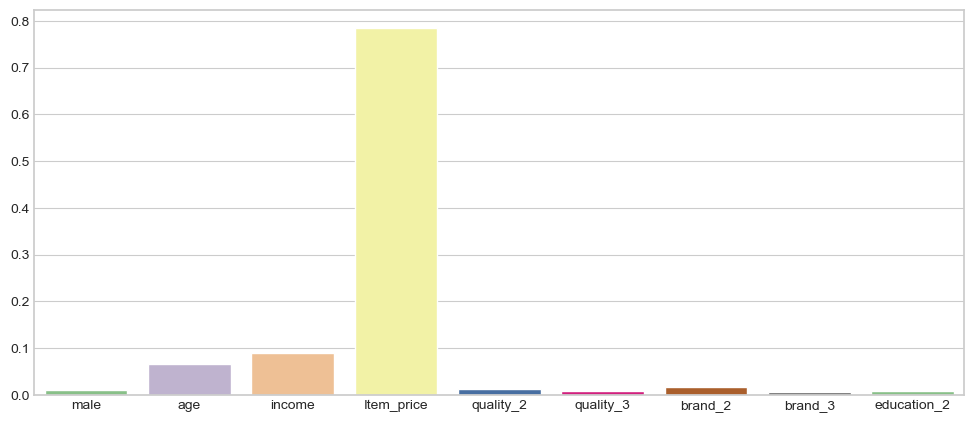

In [64]:
#Plot Searborn bar chart
plt.figure(figsize=(12,5))
sns.barplot(data=FI, palette='Accent');

In [65]:
# compute permutation_importance with test set (20 repeats) 
perm_importance = permutation_importance(model, X_test, y_test, n_repeats=20, 
                                         scoring='neg_mean_squared_error', random_state=99)
perm_importance

{'importances_mean': array([ 1.89581097e-03,  4.84829681e-03, -4.98436875e-04,  1.30954981e+00,
        -7.29321991e-03,  2.71727712e-03,  2.75558526e-03,  3.15757984e-03,
         5.47360035e-03]),
 'importances_std': array([0.0056319 , 0.00955499, 0.01407143, 0.12140133, 0.01011776,
        0.00438251, 0.00870065, 0.00276059, 0.0036634 ]),
 'importances': array([[-1.95173454e-03,  2.58495325e-03,  9.64493657e-04,
          2.62579256e-03,  2.10113952e-03, -8.74336325e-03,
          2.54503219e-03,  4.44497305e-03,  6.67835143e-03,
         -9.61324514e-03,  3.09549769e-03,  8.61780060e-03,
          5.89847100e-03,  2.44666470e-03, -2.24072597e-03,
          3.48466835e-03, -5.02328842e-03, -1.16227500e-03,
          1.56563645e-02,  5.50664927e-03],
        [-4.54694399e-03,  2.66196088e-03,  2.44251835e-03,
         -5.61378787e-03, -1.75700367e-02,  4.78990703e-03,
          7.82447707e-03, -1.08717111e-02,  2.24209114e-03,
          2.43456111e-02,  3.33372028e-03,  6.44487825e-0

In [66]:
# dataframe for "perm_importance.importances"
PFI=pd.DataFrame(perm_importance.importances, index=X_test.columns).T
PFI.shape

(20, 9)

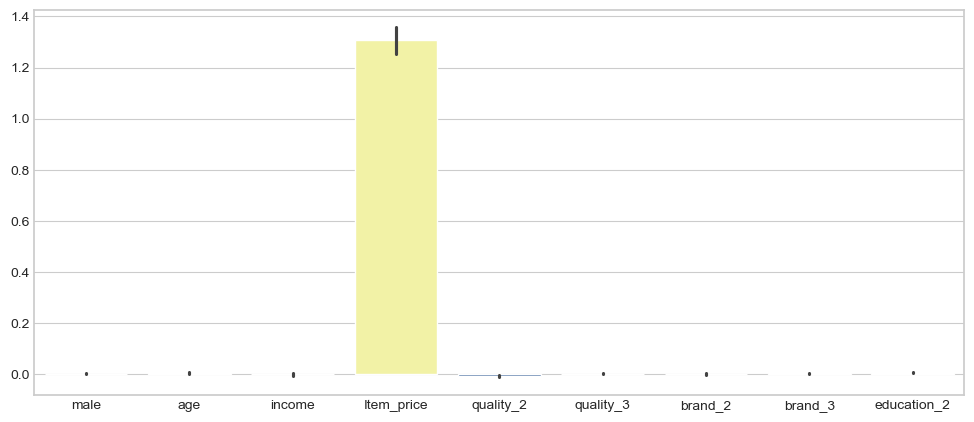

In [67]:
#Plot Searborn bar chart
plt.figure(figsize=(12,5))
sns.barplot(data=PFI,  palette='Accent');

**Discussion**

Item_price is by far the most dominant feature in predicting customer Preference, accounting for over 78% of total feature importance. It serves as the primary driver in the model.   

Income is the second most important feature, but its contribution (~8.9%) is significantly smaller than Item_price. While it plays a secondary role in explaining customer preference, it holds moderate predictive weight.   

Brand perception features contribute very little to overall prediction. Combined, brand_2 and brand_3 account for roughly 2.2% of total feature importance, indicating that shopper preference is driven mostly by item pricing and income rather than brand perception. 

# Question 2

In [68]:
#1
rp['PremiumBuyer'] = (rp['PremiumShare'] >= 0.5).astype(int)
rp.head()

,PremiumShare,ValueShare,male,age,income,Item_price,Preference,quality_2,quality_3,brand_2,brand_3,education_2,PremiumBuyer
0,0.30,0.70,1,30,75.904118,17.446430,-0.847298,True,False,False,False,False,0
1,0.60,0.40,1,71,104.654721,18.970078,0.405465,False,True,True,False,False,1
2,0.06,0.94,0,36,70.631999,14.438011,-2.751535,False,True,False,True,True,0
3,0.50,0.50,0,28,171.700623,18.535390,0.000000,True,False,False,False,True,1
4,0.50,0.50,0,23,27.081408,21.652729,0.000000,False,True,False,False,True,1


In [69]:
#2
X2, y2 = rp.drop(['PremiumShare', 'ValueShare', 'Preference', 'PremiumBuyer'], axis=1), rp['PremiumBuyer']
# set max_iter (default=100 -- might not large enough)
Logit = LogisticRegression(penalty=None, solver='lbfgs', max_iter=10000)
Logit.fit(X2, y2)

# coeffients
pd.DataFrame(Logit.coef_.round(4), columns=X2.columns)

,male,age,income,Item_price,quality_2,quality_3,brand_2,brand_3,education_2
0,0.0392,0.0062,0.0069,0.1682,-1.0824,-0.6041,0.9337,0.1738,0.0865


In [70]:
# get predicted values
yp = Logit.predict(X2)
# confusion_matrix (from sklearn.metrics)
print(confusion_matrix(y2, yp))

[[552 100]
 [108 626]]


In [71]:
# show confusionmatrix in dataframe
cm=pd.DataFrame(confusion_matrix(y2, yp), index=['Actual_0','Auctual_1'], columns=['Predicted_0','Predicted_1'])
cm

,Predicted_0,Predicted_1
Actual_0,552,100
Auctual_1,108,626


**Discussion**

For non-premium buyers (0), 552 correctly predicted, 100 wrongly predicted.

For premium buyers (1), 108 wrongly predicted, 626 correctly predicted.

3

**Increasing cutoff probability:**

TPR decreases: Making the threshold stricter makes predicting a positive outcome harder, causing the model to identify fewer actual premium buyers correctly.

FPR decreases: A higher threshold reduces false alarms, meaning non-premium buyers are less likely to be misclassified as premium buyers.

**Decreasing cutoff probability:**

TPR increases: Lowering the threshold makes predicting a positive outcome easier, capturing more actual premium buyers.

FPR increases: Being more lenient leads to misclassifying more non-premium buyers as premium buyers.

In [72]:
# get predicted probability -- two columns: col0=prob(y=0) & col1=prob(y=1)
yp_p=Logit.predict_proba(X2)

In [73]:
yp_p

array([[9.82755836e-01, 1.72441643e-02],
       [8.72369628e-01, 1.27630372e-01],
       [9.79135037e-01, 2.08649629e-02],
       ...,
       [5.56867957e-01, 4.43132043e-01],
       [2.36838069e-02, 9.76316193e-01],
       [1.15140936e-05, 9.99988486e-01]], shape=(1386, 2))

In [74]:
# roc_curve -- inputs: actual y & predicted prob(y=1)
# outputs: fpr (false positive), tpr (true positive), th (thresholds)
# fpr, tpr, th= roc_curve(y, l_prob[:,1]) 
# ROC curve use "roc_curve" from sklearn.metric
fpr, tpr, th = roc_curve(y2, yp_p[:,1])
pd.DataFrame([fpr,tpr, th]).T.head(20).round(3)

,0,1,2
0,0.000,0.000,inf
1,0.000,0.001,1.000
2,0.000,0.320,0.985
3,0.002,0.320,0.985
4,0.002,0.356,0.981
5,0.003,0.356,0.981
6,0.003,0.361,0.981
7,0.005,0.361,0.981
8,0.005,0.407,0.973
9,0.006,0.407,0.972


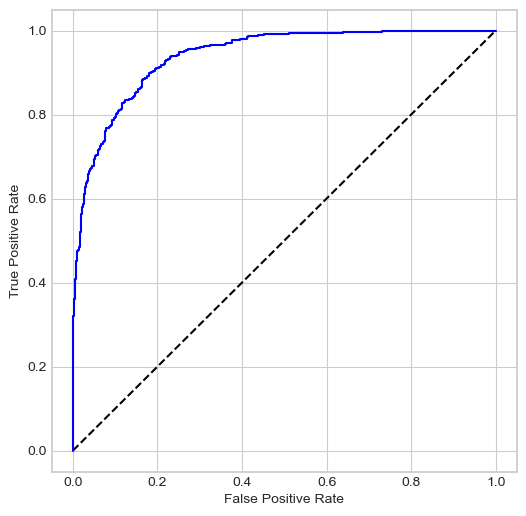

In [75]:
# ROC
pd.DataFrame([fpr,tpr, th]).T.head(20).round(3)
plt.figure(figsize=(6,6))
plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.plot(fpr, tpr, color='blue')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate');

In [76]:
# calculate AUC
round(roc_auc_score(y2, yp_p[:,1]),3)

0.94

**Discussion**

The Area Under the Curve (AUC) for the logistic regression model is 0.94.

An AUC score of 0.94 indicates excellent overall predictive performance and strong discrimination power. The blue ROC curve bows significantly toward the top-left corner, far above the dashed diagonal line. This demonstrates that the model maintains a high True Positive Rate while keeping the False Positive Rate low across various probability thresholds.

In [77]:
#4
DT4 = DecisionTreeClassifier(random_state=1867, max_depth=None, max_leaf_nodes=None)
DT4.fit(X2, y2)
# get the depth of the decision tree
print("depth:", DT4.get_depth())
print("total number of leaves", DT4.get_n_leaves())

depth: 16
total number of leaves 188


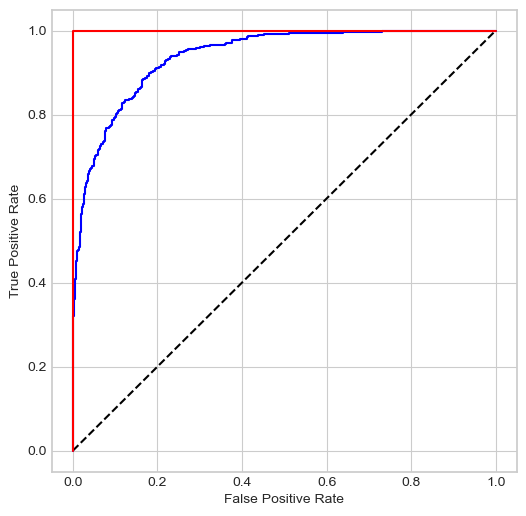

In [78]:
# get predicted probability
yp_DT4=DT4.predict_proba(X2)
fpr4, tpr4, th4 = roc_curve(y2, yp_DT4[:,1])
# ROC (logistic (blue) & decision tree (red))
plt.figure(figsize=(6,6))
plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.plot(fpr, tpr, color='blue')
plt.plot(fpr4, tpr4, color='red')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate');

**Discussion**

Tree Depth: 16

Total Number of Leaves: 188

The unconstrained decision tree generates an ROC curve (red) that hugs the top-left corner (0,1), outperforming Logistic Regression (blue) on training data. However, growing to 16 levels without restrictions causes severe overfitting, memorizing training noise and leading to poor generalization on unseen data.  

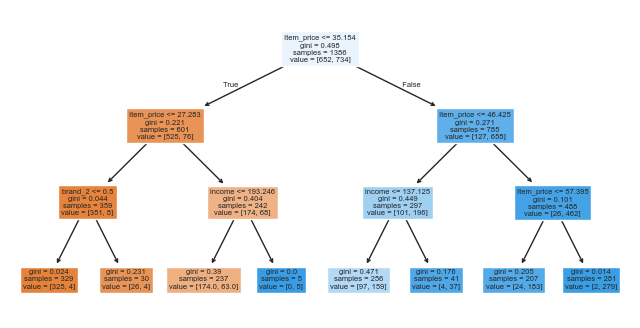

In [79]:
#5
DT5 = DecisionTreeClassifier(random_state=1867, max_depth=3, max_leaf_nodes=10)
DT5.fit(X2, y2)
fig = plt.figure(figsize=(8,4))
tree.plot_tree(DT5, feature_names=X2.columns, filled=True);

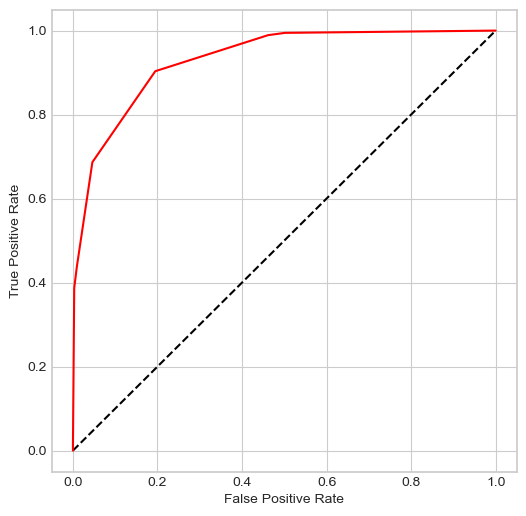

In [80]:
# get predicted probability
yp_DT5=DT5.predict_proba(X2)
fpr5, tpr5, th5 = roc_curve(y2, yp_DT5[:,1])
# ROC 
plt.figure(figsize=(6,6))
plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.plot(fpr5, tpr5, color='red')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate');

**Discussion**

Restricting depth to 3 creates a simple, interpretable tree where Item_price serves as the primary root split.

Unlike the unconstrained Part 4 tree that overfit the training data to reach (0, 1), setting max_depth=3 regularizes the model and improves generalization to new data.

The decision tree creates a step-like ROC curve due to discrete leaf probabilities, whereas Logistic Regression produces a smooth, continuous curve. Both show strong performance, but Logistic Regression offers more consistent probability estimates across cutoff thresholds.   

In [34]:
#6
# sklearn neural network models
from sklearn.neural_network import MLPClassifier, MLPRegressor

# install& import SHAP 
!pip install shap
import shap

In [35]:
# MLP, classifier (default, except for max_iter=10000)
# default: one hiiden layer with "100" neurons
NN = MLPClassifier(random_state=1867, max_iter=10000, hidden_layer_sizes=(100))
pipe_NN = make_pipeline(StandardScaler(), NN)

X2float = X2.astype(float)
# "values" only for X (to avoid warning)
pipe_NN.fit(X2float.values, y2)

# shap Explainer
explainer = shap.Explainer(pipe_NN.predict, X2float.values)
shap_values = explainer(X2float.values)
shap_values

Background dataset has 1386 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1386 when initializing the masker.
ExactExplainer explainer: 1387it [00:14, 36.14it/s]                                                                     


.values =
array([[-0.0035    , -0.00952381, -0.0167381 , ..., -0.00630952,
         0.003     , -0.00595238],
       [ 0.08949603,  0.14975794,  0.1324127 , ...,  0.17606746,
         0.02790079,  0.07072222],
       [-0.01192857, -0.00888095, -0.01838095, ...,  0.00054762,
        -0.0017619 ,  0.01304762],
       ...,
       [ 0.04183333, -0.01983333, -0.19033333, ..., -0.04471429,
        -0.05095238, -0.11366667],
       [-0.0062619 , -0.0265    , -0.0187619 , ..., -0.00419048,
        -0.00652381,  0.001     ],
       [ 0.00345238,  0.0062619 , -0.0152619 , ..., -0.00410714,
        -0.00753571,  0.00069048]], shape=(1386, 9))

.base_values =
array([0.56, 0.56, 0.56, ..., 0.56, 0.56, 0.56], shape=(1386,))

.data =
array([[  1.        ,  30.        ,  75.90411796, ...,   0.        ,
          0.        ,   0.        ],
       [  1.        ,  71.        , 104.6547215 , ...,   1.        ,
          0.        ,   0.        ],
       [  0.        ,  36.        ,  70.63199946, ...,   0.

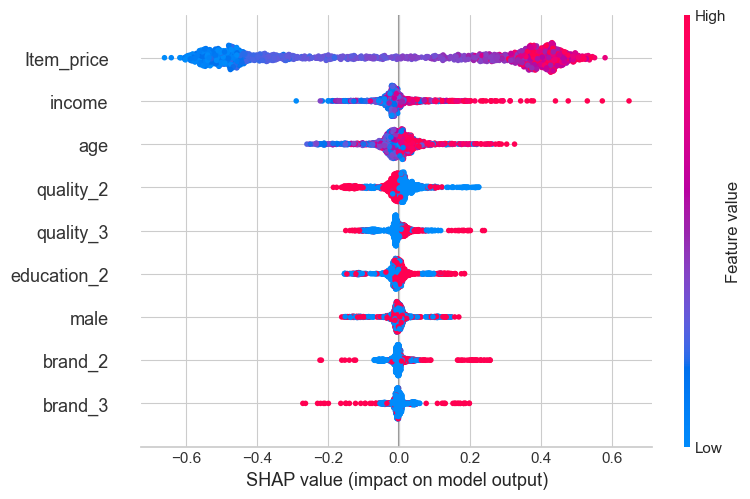

In [36]:
# summary_plot
# plot_type='dot' (default); try "violin" & "bar"
shap.summary_plot(shap_values, Xfloat, feature_names=Xfloat.columns, plot_type='dot')

**Discussion**

Item_price and income show the widest spread of SHAP values, identifying them as the most influential predictors of becoming a premium buyer.   

High values of Item_price and income shift SHAP values strongly to the right (positive), indicating that higher prices and incomes significantly increase the likelihood of being a PremiumBuyer.   